# Exploratory Data Analysis — MSL (Mars Science Laboratory)
Dataset MSL merupakan data telemetri dari Mars Science Laboratory (Curiosity rover) milik NASA. Setiap *channel* merepresentasikan satu sensor onboard. Anomali pada dataset ini bersifat **point** dan **contextual** yang telah dilabeli secara manual oleh para ahli NASA.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from pathlib import Path
import ast, warnings, os
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'lines.linewidth': 0.9,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

BASE = Path(r'D:\CARLA')
COLORS = {'normal': '#2196F3', 'anomaly': '#FF5722', 'val': '#4CAF50'}

# Buat folder output jika belum ada
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Setup selesai. Output gambar: {FIG_DIR}')


Setup selesai. Output gambar: D:\CARLA\results\figures


## 1. Memuat Metadata

In [6]:
DATA_DIR = BASE / 'datasets' / 'MSL_SMAP'
df_labels = pd.read_csv(DATA_DIR / 'labeled_anomalies.csv')
msl = df_labels[df_labels['spacecraft'] == 'MSL'].copy()
msl = msl.reset_index(drop=True)

print(f"Jumlah channel MSL : {len(msl)}")
print(f"\nKolom tersedia    : {list(msl.columns)}")
print()
display(msl[['chan_id','class','num_values','anomaly_sequences']].head(10))


Jumlah channel MSL : 27

Kolom tersedia    : ['chan_id', 'spacecraft', 'anomaly_sequences', 'class', 'num_values']



,chan_id,class,num_values,anomaly_sequences
0,M-6,[point],2049,"[[1850, 2030]]"
1,M-1,[contextual],2277,"[[1110, 2250]]"
2,M-2,[contextual],2277,"[[1110, 2250]]"
3,S-2,[point],1827,"[[900, 910]]"
4,P-10,[point],6100,"[[4590, 4720]]"
5,T-4,[point],2217,"[[1172, 1240]]"
6,T-5,[point],2218,"[[1200, 1225]]"
7,F-7,"[contextual, contextual, contextual]",5054,"[[1250, 1450], [2670, 2790], [3325, 3425]]"
8,M-3,[contextual],2127,"[[1250, 1500]]"
9,M-4,[contextual],2038,"[[1250, 1500]]"


## 2. Distribusi Panjang Deret Waktu per Channel

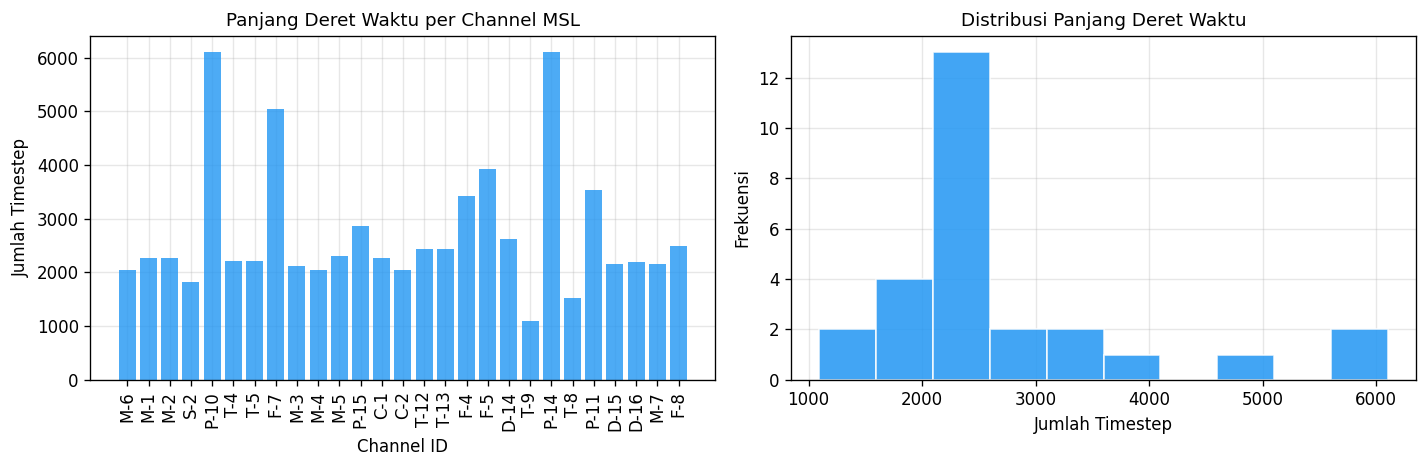


Statistik panjang deret waktu:
count      27.0
mean     2730.7
std      1239.3
min      1096.0
25%      2141.5
50%      2277.0
75%      2740.5
max      6100.0


In [7]:
lengths = msl['num_values'].values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(msl['chan_id'], lengths, color=COLORS['normal'], alpha=0.8)
axes[0].set_xlabel('Channel ID')
axes[0].set_ylabel('Jumlah Timestep')
axes[0].set_title('Panjang Deret Waktu per Channel MSL')
axes[0].tick_params(axis='x', rotation=90)

axes[1].hist(lengths, bins=10, color=COLORS['normal'], edgecolor='white', alpha=0.85)
axes[1].set_xlabel('Jumlah Timestep')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Panjang Deret Waktu')
for ax in axes:
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_msl_lengths.png', bbox_inches='tight')
plt.show()
print(f"\nStatistik panjang deret waktu:")
print(pd.Series(lengths).describe().round(1).to_string())


## 3. Distribusi Tipe Anomali

Tipe anomali MSL:
  point          : 19 segmen
  contextual     : 17 segmen


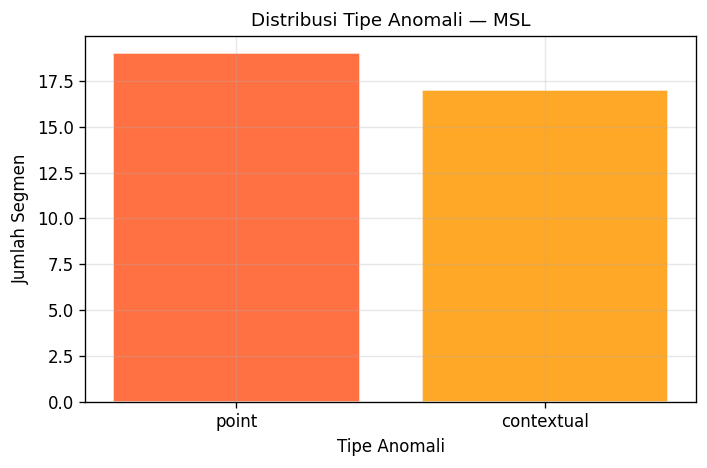

In [8]:
import re
def parse_class(c):
    # class column mungkin berisi identifier tak-quoted: [point, contextual]
    return re.findall(r'[A-Za-z_][A-Za-z0-9_]*', str(c))

all_types = []
for _, row in msl.iterrows():
    all_types.extend(parse_class(row['class']))

from collections import Counter
type_counts = Counter(all_types)
print("Tipe anomali MSL:")
for k, v in type_counts.items():
    print(f"  {k:15s}: {v} segmen")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(type_counts.keys(), type_counts.values(),
       color=[COLORS['anomaly'], '#FF9800'], edgecolor='white', alpha=0.85)
ax.set_xlabel('Tipe Anomali')
ax.set_ylabel('Jumlah Segmen')
ax.set_title('Distribusi Tipe Anomali — MSL')
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_msl_anomaly_types.png', bbox_inches='tight')
plt.show()


## 4. Visualisasi Sampel Channel (Normal vs Anomali)

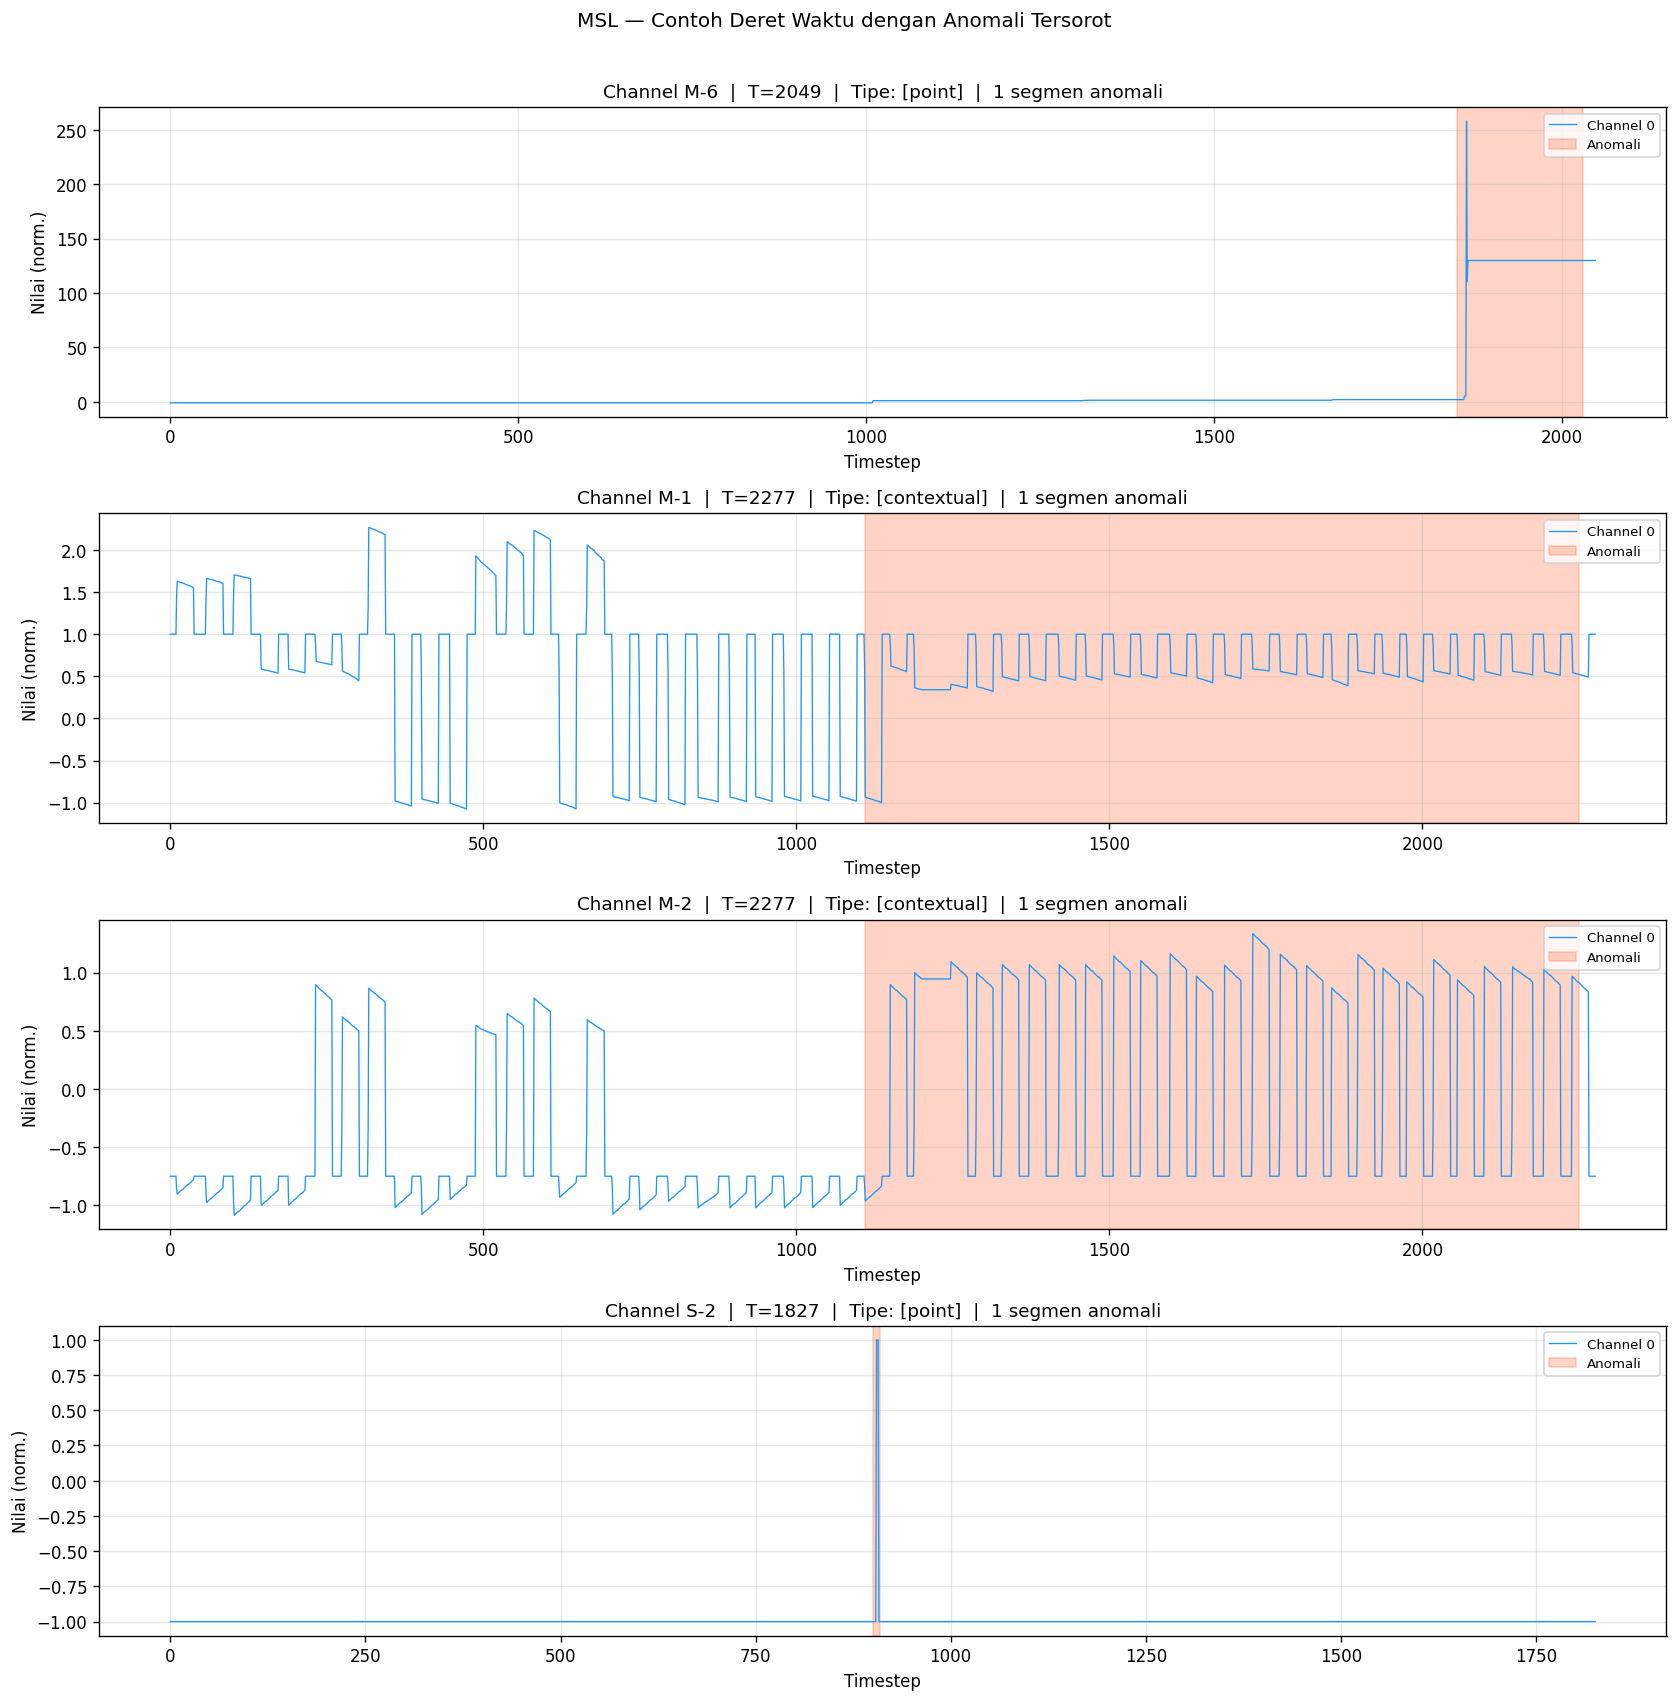

In [9]:
def load_msl(chan_id, split='test'):
    path = DATA_DIR / 'data' / split / f'{chan_id}.npy'
    return np.load(path)

def parse_anomaly_seqs(seq_str):
    return ast.literal_eval(seq_str)

# Ambil 4 channel sampel
sample_chans = msl['chan_id'].iloc[:4].tolist()
fig, axes = plt.subplots(len(sample_chans), 1, figsize=(14, 3.5 * len(sample_chans)))
if len(sample_chans) == 1:
    axes = [axes]

for ax, chan_id in zip(axes, sample_chans):
    row = msl[msl['chan_id'] == chan_id].iloc[0]
    data = load_msl(chan_id, 'test')   # (T, 25)
    T = data.shape[0]
    t = np.arange(T)

    # Plot channel pertama sebagai representasi
    ax.plot(t, data[:, 0], color=COLORS['normal'], linewidth=0.8, label='Channel 0')

    # Highlight anomali
    seqs = parse_anomaly_seqs(row['anomaly_sequences'])
    for i, (s, e) in enumerate(seqs):
        ax.axvspan(s, e, color=COLORS['anomaly'], alpha=0.25,
                   label='Anomali' if i == 0 else '_')

    ax.set_title(f'Channel {chan_id}  |  T={T}  |  '
                 f"Tipe: {row['class']}  |  {len(seqs)} segmen anomali")
    ax.set_xlabel('Timestep')
    ax.set_ylabel('Nilai (norm.)')
    ax.legend(fontsize=8, loc='upper right')

plt.suptitle('MSL — Contoh Deret Waktu dengan Anomali Tersorot', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_msl_timeseries.png', bbox_inches='tight')
plt.show()


## 5. Rasio Anomali per Channel

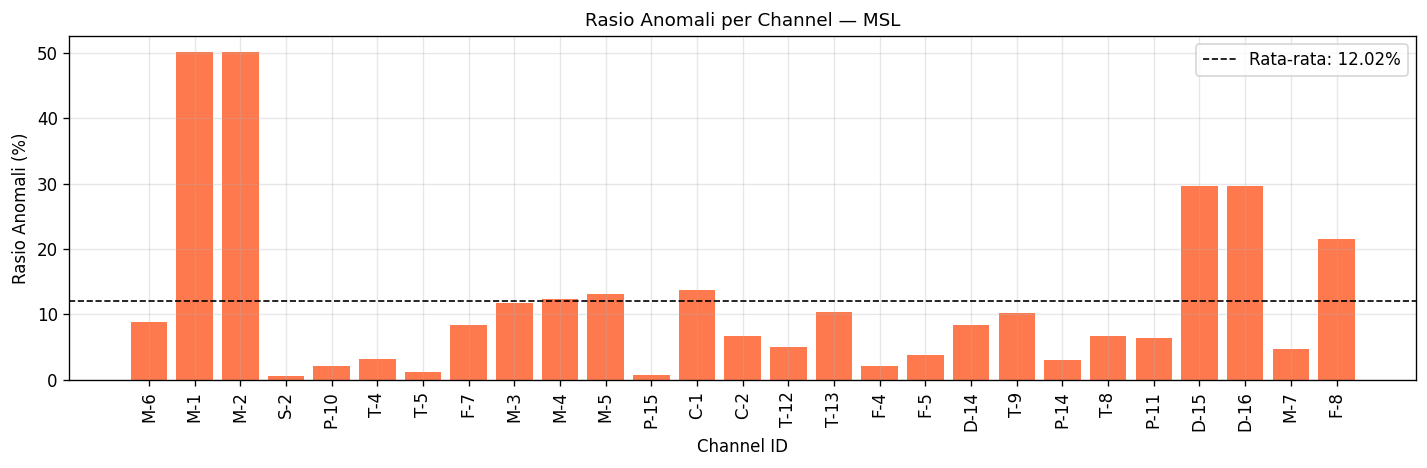

Rata-rata rasio anomali : 12.02%
Min: 0.60%  Max: 50.11%


In [10]:
anomaly_ratios = []
for _, row in msl.iterrows():
    T = row['num_values']
    seqs = parse_anomaly_seqs(row['anomaly_sequences'])
    n_anom = sum(e - s + 1 for s, e in seqs)
    anomaly_ratios.append(n_anom / T * 100)

msl['anomaly_ratio_%'] = anomaly_ratios

fig, ax = plt.subplots(figsize=(12, 4))
bars = ax.bar(msl['chan_id'], msl['anomaly_ratio_%'],
              color=COLORS['anomaly'], alpha=0.8)
ax.axhline(np.mean(anomaly_ratios), color='black', linestyle='--', linewidth=1,
           label=f'Rata-rata: {np.mean(anomaly_ratios):.2f}%')
ax.set_xlabel('Channel ID')
ax.set_ylabel('Rasio Anomali (%)')
ax.set_title('Rasio Anomali per Channel — MSL')
ax.tick_params(axis='x', rotation=90)
ax.legend()
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_msl_anomaly_ratio.png', bbox_inches='tight')
plt.show()

print(f"Rata-rata rasio anomali : {np.mean(anomaly_ratios):.2f}%")
print(f"Min: {np.min(anomaly_ratios):.2f}%  Max: {np.max(anomaly_ratios):.2f}%")


## 6. Statistik Fitur (Channel P-1 sebagai Representasi)

In [11]:
chan = 'P-1'
train_data = load_msl(chan, 'train')  # (T_train, 25)
test_data  = load_msl(chan, 'test')   # (T_test,  25)

print(f"Channel {chan}:")
print(f"  Train shape : {train_data.shape}")
print(f"  Test shape  : {test_data.shape}")
print(f"  Jumlah fitur: {train_data.shape[1]}")

# Statistik deskriptif 25 fitur dari data train
df_stats = pd.DataFrame(train_data,
    columns=[f'F{i}' for i in range(train_data.shape[1])])
stats = df_stats.describe().T
stats['skewness'] = df_stats.skew()
stats['kurtosis'] = df_stats.kurt()
print(f"\nStatistik deskriptif {train_data.shape[1]} fitur (data train):")
display(stats[['mean','std','min','max','skewness','kurtosis']].round(4).head(10))


Channel P-1:
  Train shape : (2872, 25)
  Test shape  : (8505, 25)
  Jumlah fitur: 25

Statistik deskriptif 25 fitur (data train):


,mean,std,min,max,skewness,kurtosis
F0,-0.4272,0.4028,-1.0,1.0,1.1491,0.6852
F1,0.0341,0.1816,0.0,1.0,5.1351,24.3860
F2,0.0059,0.0767,0.0,1.0,12.8888,164.2350
F3,0.0279,0.1646,0.0,1.0,5.7413,30.9847
F4,0.0000,0.0000,0.0,0.0,0.0000,0.0000
F5,0.1574,0.3642,0.0,1.0,1.8827,1.5455
F6,0.1229,0.3284,0.0,1.0,2.2982,3.2839
F7,0.0014,0.0373,0.0,1.0,26.7535,714.2463
F8,0.0000,0.0000,0.0,0.0,0.0000,0.0000
F9,0.0007,0.0264,0.0,1.0,37.8748,1433.4972


## 7. Heatmap Korelasi Antar Fitur

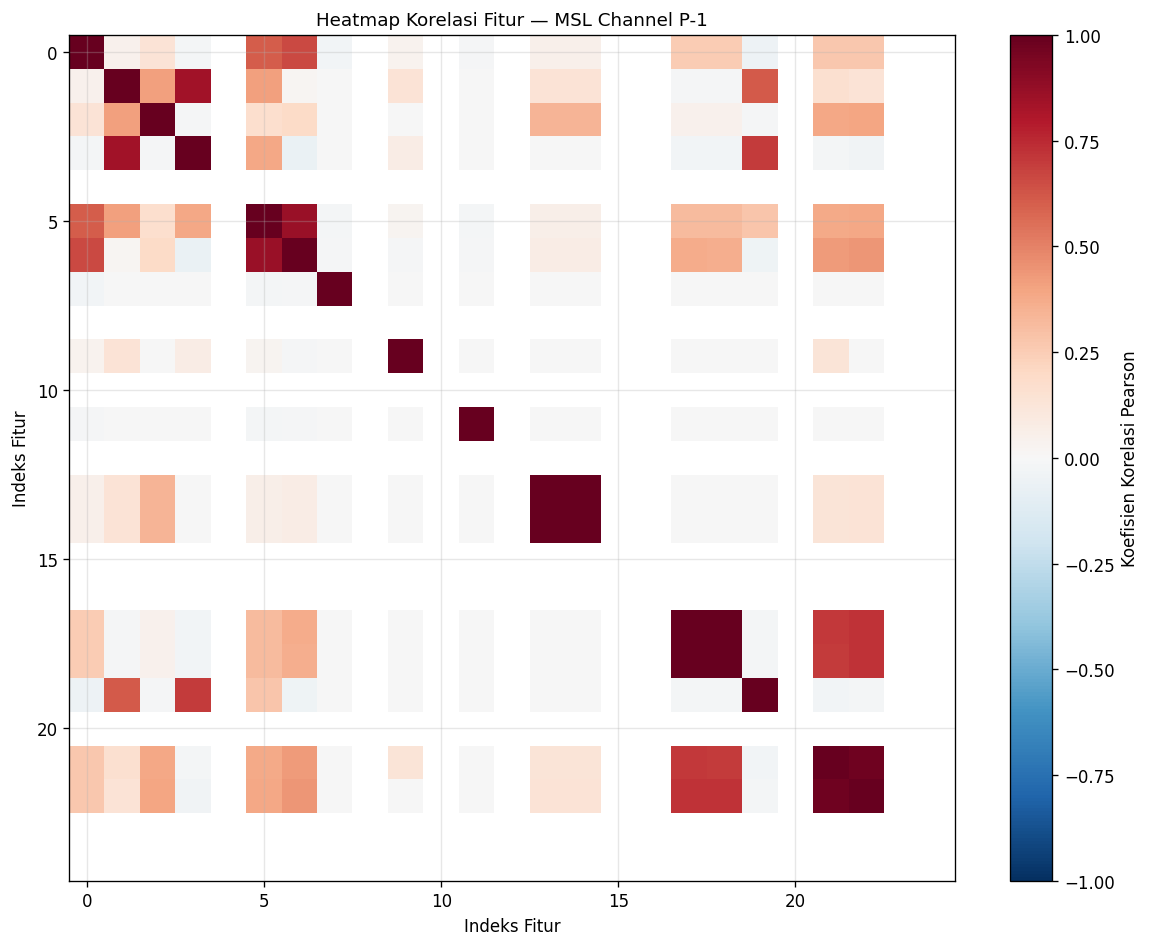

Pasangan fitur dengan |korelasi| > 0.7: 5


In [12]:
import matplotlib.colors as mcolors

chan = 'P-1'
train_data = load_msl(chan, 'train')
corr = np.corrcoef(train_data.T)  # (25, 25)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, label='Koefisien Korelasi Pearson')
ax.set_title(f'Heatmap Korelasi Fitur — MSL Channel {chan}')
ax.set_xlabel('Indeks Fitur')
ax.set_ylabel('Indeks Fitur')
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_msl_correlation.png', bbox_inches='tight')
plt.show()

strong = np.sum(np.abs(corr) > 0.7) - corr.shape[0]
print(f"Pasangan fitur dengan |korelasi| > 0.7: {strong // 2}")


## 8. Ringkasan Dataset MSL

In [13]:
print("=" * 50)
print("RINGKASAN DATASET MSL")
print("=" * 50)
print(f"Jumlah channel          : {len(msl)}")
print(f"Jumlah fitur per sample : 25")
print(f"Rata-rata panjang test  : {msl['num_values'].mean():.0f} timestep")
print(f"Total segmen anomali    : {sum(len(parse_anomaly_seqs(r)) for r in msl['anomaly_sequences'])}")
print(f"Rata-rata rasio anomali : {np.mean(anomaly_ratios):.2f}%")
print(f"Tipe anomali            : point, contextual")


RINGKASAN DATASET MSL
Jumlah channel          : 27
Jumlah fitur per sample : 25
Rata-rata panjang test  : 2731 timestep
Total segmen anomali    : 36
Rata-rata rasio anomali : 12.02%
Tipe anomali            : point, contextual
